# # Classifiers comparison: decision trees and k-nearest neighbors on the dataset Iris


In the following program we compare the prediction results obtained by decision trees and k-nearest neighbors on the dataset Iris

The following cell shows the program training a decision tree and its results in preciction

In [1]:
from sklearn import tree
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score # will be used to separate training and test
iris = load_iris()
clf = tree.DecisionTreeClassifier(criterion="entropy",random_state=300,min_samples_leaf=5,class_weight={0:1,1:1,2:1})
clf = clf.fit(iris.data, iris.target)
scores = cross_val_score(clf, iris.data, iris.target, cv=5) # score will be the accuracy
print(scores)


[0.96666667 1.         0.86666667 0.86666667 1.        ]


The following cell shows the training of k-nearest neighbors and its prediction results.
Here we use a uniform weighting setting (weights='uniform'): any neighbors weights the same in the majority voting aggregation.

In [2]:
from sklearn import neighbors
import pandas as pd
n_neighbors = 11
clf_knn = neighbors.KNeighborsClassifier(n_neighbors, weights='uniform')
clf_knn = clf_knn.fit(iris.data, iris.target)
scores = cross_val_score(clf_knn, iris.data, iris.target, cv=5) # score will be the accuracy
print(scores)
# shows the model predictions with pandas
k_nn_results = []

for i in range(len(iris.target)):
    instance=(iris.data[i,:]).reshape(1, -1)
    predicted=clf_knn.predict(instance)[0]
    k_nn_results.append({
        'Instance': i,
        iris.feature_names[0]: iris.data[i,0],
        iris.feature_names[1]: iris.data[i,1],
        iris.feature_names[2]: iris.data[i,2],
        iris.feature_names[3]: iris.data[i,3],
        'Predicted class': iris.target_names[predicted],
        'True class': iris.target_names[iris.target[i]],
        'Correct': 'Yes' if predicted == iris.target[i] else 'No'
    })

results_df = pd.DataFrame(k_nn_results)
print(results_df.to_string(index=False, float_format='%.1f'))

[0.93333333 1.         1.         0.96666667 1.        ]
 Instance  sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) Predicted class True class Correct
        0                5.1               3.5                1.4               0.2          setosa     setosa     Yes
        1                4.9               3.0                1.4               0.2          setosa     setosa     Yes
        2                4.7               3.2                1.3               0.2          setosa     setosa     Yes
        3                4.6               3.1                1.5               0.2          setosa     setosa     Yes
        4                5.0               3.6                1.4               0.2          setosa     setosa     Yes
        5                5.4               3.9                1.7               0.4          setosa     setosa     Yes
        6                4.6               3.4                1.4               0.3          setosa     setosa

In the following cell we use a varying weighting setting (weights='distance'): any neighbors weights inversely with its distance to the test instance in the majority voting aggregation.

In [3]:
n_neighbors = 11
clf_knn2 = neighbors.KNeighborsClassifier(n_neighbors, weights='distance')
clf_knn2.fit(iris.data, iris.target)
scores2 = cross_val_score(clf_knn2, iris.data, iris.target, cv=5) # score will be the accuracy
print(scores2)

# shows the model predictions with pandas
k_nn2_results = []

for i in range(len(iris.target)):
    instance=(iris.data[i,:]).reshape(1, -1)
    predicted=clf_knn2.predict(instance)[0]
    k_nn2_results.append({
        'Instance': i,
        iris.feature_names[0]: iris.data[i,0],
        iris.feature_names[1]: iris.data[i,1],
        iris.feature_names[2]: iris.data[i,2],
        iris.feature_names[3]: iris.data[i,3],
        'Predicted class': iris.target_names[predicted],
        'True class': iris.target_names[iris.target[i]],
        'Correct': 'Yes' if predicted == iris.target[i] else 'No'
    })

results_df = pd.DataFrame(k_nn2_results)
print(results_df.to_string(index=False, float_format='%.1f'))

[0.96666667 1.         1.         0.96666667 1.        ]
 Instance  sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) Predicted class True class Correct
        0                5.1               3.5                1.4               0.2          setosa     setosa     Yes
        1                4.9               3.0                1.4               0.2          setosa     setosa     Yes
        2                4.7               3.2                1.3               0.2          setosa     setosa     Yes
        3                4.6               3.1                1.5               0.2          setosa     setosa     Yes
        4                5.0               3.6                1.4               0.2          setosa     setosa     Yes
        5                5.4               3.9                1.7               0.4          setosa     setosa     Yes
        6                4.6               3.4                1.4               0.3          setosa     setosa

The following cell shows the tuning of the k-nn models with a varying value of k (number of nearest neighbors) and finds the best value of k (giving the maximum accuracy).



best k=7
best accuracy=0.9666666666666667


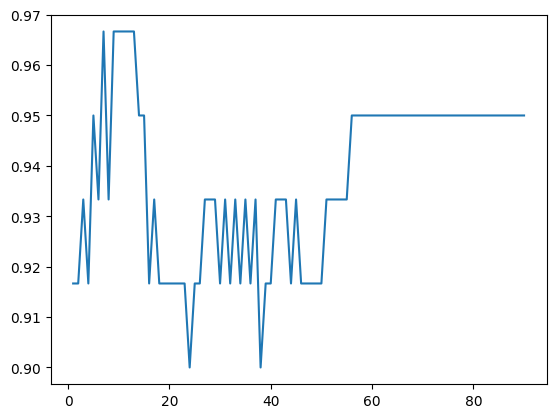

In [4]:
import numpy as np
from numpy import zeros
from sklearn import neighbors
from sklearn.datasets import load_iris
iris = load_iris()
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)

best_accuracy=0
best_k=1
A=np.zeros(len(y_train), dtype=np.float64) # for storing accuracies
for n_neighbors in np.arange(1,len(y_train)+1):
    clf_knn3 = neighbors.KNeighborsClassifier(n_neighbors, weights='distance')
    # (n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=1, **kwargs)
    clf_knn3.fit(X_train, y_train)
    index=n_neighbors-1
    A[index]=clf_knn3.score(X_test, y_test)
    if best_accuracy<clf_knn3.score(X_test, y_test):
        best_accuracy=clf_knn3.score(X_test, y_test)
        best_k=n_neighbors
    #print("k neighbors="+str(n_neighbors))
    #print("accuracy="+str(clf_knn3.score(X_test, y_test)))

print("\n")
print("best k="+str(best_k))
print("best accuracy="+str(best_accuracy))

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

#plt.xticks(np.arange(1, len(y_train)+1, 8))
plt.yticks(np.arange(0.0,1.0,0.01))

plt.plot(np.arange(1,len(y_train)+1),A)

plt.show()

In the following cell we plot in the same plot two subplots with the diagrams on accuracy with the two kinds of weighting
of the vote of the neighbours (uniform and with distance)

weighting:uniform


best k=7
best accuracy=0.9666666666666667
weighting:distance


best k=7
best accuracy=0.9666666666666667


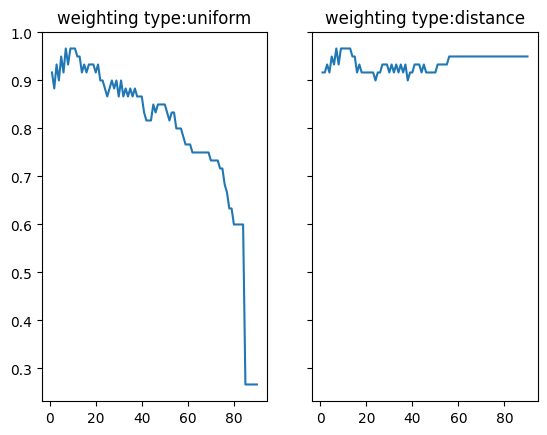

In [5]:
import numpy as np
from numpy import zeros
from sklearn import neighbors
from sklearn.datasets import load_iris
iris = load_iris()
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)

i=0  #parameter in the control of the subplot to draw on'
f,(ax1, ax2) = plt.subplots(1, 2, sharey=True)
for weight_type in ['uniform','distance']:
    print("weighting:"+str(weight_type))
    A=np.zeros(len(y_train), dtype=np.float64) # for storing accuracies
    best_accuracy=0
    best_k=1
    for n_neighbors in np.arange(1,len(y_train)+1):
        clf_knn2 = neighbors.KNeighborsClassifier(n_neighbors, weights=weight_type)
        # (n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=1, **kwargs)
        clf_knn2.fit(X_train, y_train)
        index=n_neighbors-1
        A[index]=clf_knn2.score(X_test, y_test)
        if best_accuracy<clf_knn2.score(X_test, y_test):
            best_accuracy=clf_knn2.score(X_test, y_test)
            best_k=n_neighbors
        #print("k neighbors="+str(n_neighbors))
        #print("accuracy="+str(clf_knn2.score(X_test, y_test)))

    print("\n")
    print("best k="+str(best_k))
    print("best accuracy="+str(best_accuracy))
    if i==0:
        ax1.plot(np.arange(1,len(y_train)+1),A)
        ax1.set_title('weighting type:'+str(weight_type))
    else:
        ax2.plot(np.arange(1,len(y_train)+1),A)
        ax2.set_title('weighting type:'+str(weight_type))
    i=i+1

plt.show()


In the following cell we plot (overlapping) in the same picture both the diagrams on accuracy with the two kinds of weighting
of the vote of the neighbours (uniform and with distance)


 weighting:uniform
best k=7
best accuracy=0.9666666666666667

 weighting:distance
best k=7
best accuracy=0.9666666666666667


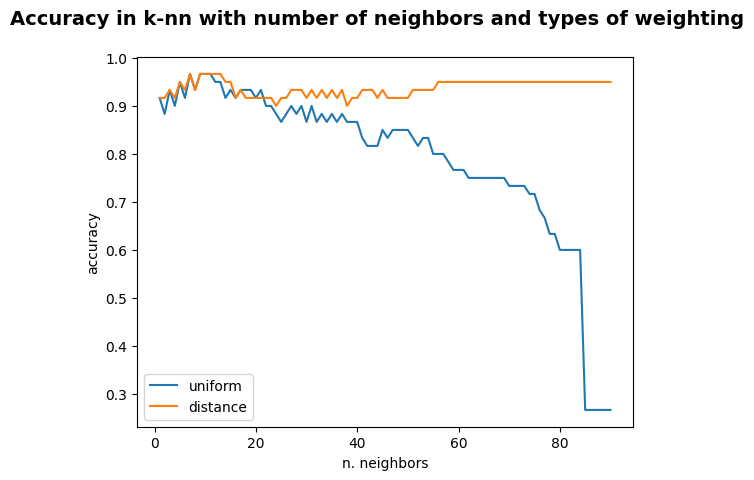

In [6]:
import numpy as np
from numpy import zeros
from sklearn import neighbors
from sklearn.datasets import load_iris
iris = load_iris()
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)

fig = plt.figure()
fig.suptitle('Accuracy in k-nn with number of neighbors and types of weighting', fontsize=14, fontweight='bold')
ax = fig.add_subplot(111)
ax.set_xlabel('n. neighbors')
ax.set_ylabel('accuracy')

A=np.zeros((len(y_train),2), dtype=np.float64) # 2 arrays for storing accuracies for each type of weigthing
i=0  #parameter in the control of the different diagram (=matrix A column index)
best_accuracy=0
for weight_type in ['uniform','distance']:
    print("\n weighting:"+str(weight_type))
    best_accuracy=0
    best_k=1
    for n_neighbors in np.arange(1,len(y_train)+1):
        clf_knn2 = neighbors.KNeighborsClassifier(n_neighbors, weights=weight_type)
        # (n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=1, **kwargs)
        clf_knn2.fit(X_train, y_train)
        index=n_neighbors-1 # computes the matrix row index
        A[index,i]=clf_knn2.score(X_test, y_test)
        if best_accuracy<clf_knn2.score(X_test, y_test):
            best_accuracy=clf_knn2.score(X_test, y_test)
            best_k=n_neighbors
        #print("k neighbors="+str(n_neighbors))
        #print("accuracy="+str(clf_knn2.score(X_test, y_test)))

    print("best k="+str(best_k))
    print("best accuracy="+str(best_accuracy))
    plt.plot(np.arange(1,len(y_train)+1),A[:,i])
    i=i+1
plt.legend(['uniform', 'distance'], loc='lower left')
plt.show()


Plot the Iris dataset, in 2-D, with a red color for Setosa, blu for Versicolor, Green for Virginica. Choose in a way decided by you, the best subset of 2 features to plot the Iris data so that the classes are separated the most.


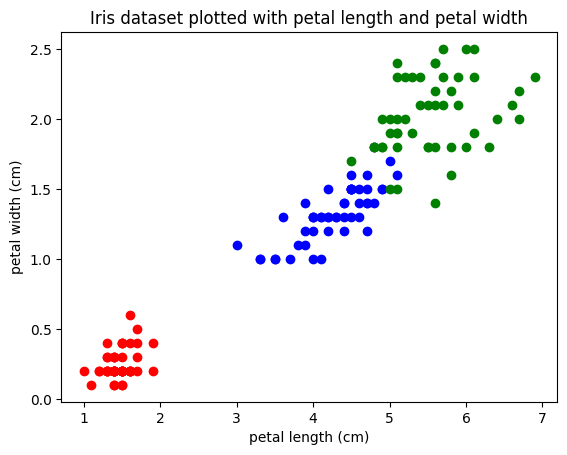

In [10]:
import matplotlib.pyplot as plt
iris = load_iris()
plt.figure()
for i in range(len(iris.target)):
    if iris.target[i]==0:
        plt.scatter(iris.data[i,2], iris.data[i,3], color='red')
    elif iris.target[i]==1:
        plt.scatter(iris.data[i,2], iris.data[i,3], color='blue')
    else:
        plt.scatter(iris.data[i,2], iris.data[i,3], color='green')
plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title('Iris dataset plotted with petal length and petal width')
plt.show() 


Plot the Iris dataset, in 2-D, with the color as above determined by the k-nn estimation


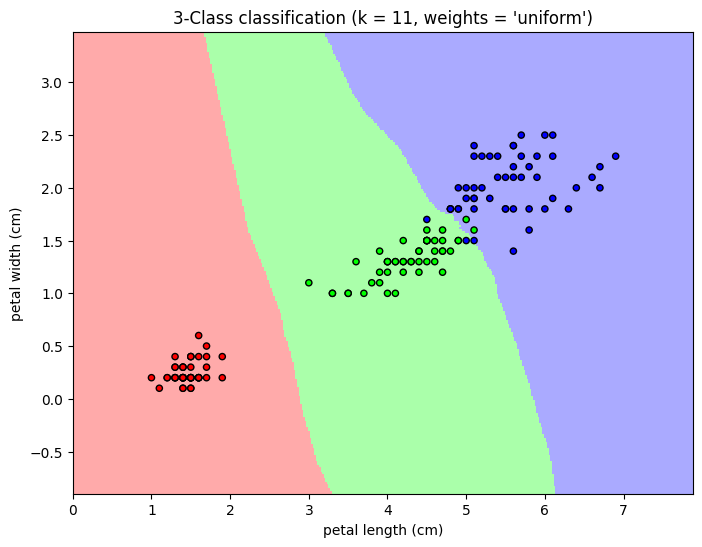

In [11]:
import numpy as np
from matplotlib.colors import ListedColormap
from sklearn import neighbors

# 1. Preparazione dati (Feature 2 e 3)
X = iris.data[:, [2, 3]]
y = iris.target
h = .02  # step size nella mesh

# 2. Creazione e training del modello
n_neighbors = 11
clf = neighbors.KNeighborsClassifier(n_neighbors, weights='uniform')
clf.fit(X, y)

# 3. Creazione della griglia per il colore di sfondo
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# 4. Predizione su ogni punto della griglia
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. Plotting
plt.figure(figsize=(8, 6))
plt.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto')

# Plot anche dei punti di training reali
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title(f"3-Class classification (k = {n_neighbors}, weights = 'uniform')")
plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.show()

In the following, extend the above exercize on k-nn using metric learning.
Use a kernel function for the distances computation.
Use $K(x_t, x_n) = exp(-\gamma ||x_t-x_n||^2)$ were $\gamma$ is the inverse of the variance. Its best value is the purpose of this cell, and it will be determined by you according to the accuracy on Iris. If you want to convert a Gaussian kernel into a distance you can use one of these formulas below:

1.   $d(x_t,x_n)=\sqrt{-\frac{1}{\gamma}*ln(K(x_t,x_n))}$
2.   $d(x_t,x_n)=\sqrt{K(x_t,x_t)-2*K(x_t,x_n)+K(x_n,x_n)}$


Searching for best gamma...
Gamma: 0.001, Accuracy: 0.9667
Gamma: 0.01, Accuracy: 0.9667
Gamma: 0.1, Accuracy: 0.9667
Gamma: 0.5, Accuracy: 0.9667
Gamma: 1, Accuracy: 0.9667
Gamma: 2, Accuracy: 0.9667
Gamma: 5, Accuracy: 0.9667
Gamma: 10, Accuracy: 0.9667
Gamma: 100, Accuracy: 0.9333
Gamma: 1000, Accuracy: 0.4333
Gamma: 10000, Accuracy: 0.3833

Best Gamma: 0.001 with Accuracy: 0.9667


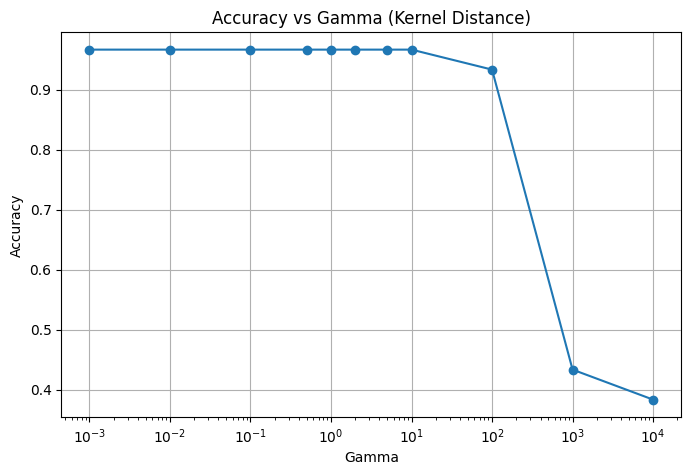

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import math

# 1. Definizione della distanza custom basata su Kernel
def kernel_distance(x, y, gamma=1.0):
    # Calcolo distanza euclidea al quadrato
    sq_dist = np.sum((x - y) ** 2)
    # Calcolo Kernel K(x,y)
    k_xy = np.exp(-gamma * sq_dist)
    # Dato che K(x,x) = 1 e K(y,y) = 1 per RBF, la formula diventa:
    # d = sqrt(1 - 2K(x,y) + 1) = sqrt(2 - 2K(x,y))
    # Aggiungiamo un piccolo epsilon o max(0, ...) per evitare errori numerici sotto radice
    val = 2 - 2 * k_xy
    return np.sqrt(max(0, val))

# 2. Setup dati
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)

# 3. Ricerca del miglior Gamma
gammas = [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 100, 1000, 10000]
best_acc = 0
best_gamma = 0
accuracies = []

print("Searching for best gamma...")

for g in gammas:
    # Creiamo una funzione lambda per passare 'gamma' alla metrica
    # Sklearn vuole che la metrica accetti solo (x, y)
    my_metric = lambda x, y: kernel_distance(x, y, gamma=g)
    
    # Usiamo algorithm='brute' perché i tree-based non supportano metriche custom
    clf = neighbors.KNeighborsClassifier(n_neighbors=11, metric=my_metric,weights='distance', algorithm='brute')
    
    clf.fit(X_train, y_train)
    acc = clf.score(X_test, y_test)
    accuracies.append(acc)
    
    print(f"Gamma: {g}, Accuracy: {acc:.4f}")
    
    if acc > best_acc:
        best_acc = acc
        best_gamma = g

print(f"\nBest Gamma: {best_gamma} with Accuracy: {best_acc:.4f}")

# 4. Plot dei risultati
plt.figure(figsize=(8, 5))
plt.plot(gammas, accuracies, marker='o')
plt.xscale('log') # Scala logaritmica per vedere meglio i vari ordini di grandezza
plt.xlabel('Gamma')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Gamma (Kernel Distance)')
plt.grid(True)
plt.show()